# Influencer Fraud Detection

Objective :  Analyze influencer profiles and use machine learning to identify suspicious engagement patterns, detect potential fraud, and generate fraud risk scores.

Dataset :  Influencer-Fraud Detection.csv

The aim is to classify influencer profiles as **Normal (0)** or **Potentially Fraudulent (1)** based on unusual patterns in followers, engagement, and growth metrics using Isolation Forest and Local Outlier Factor (LOF).

# Data Loading and Understanding

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score
from sklearn.metrics import precision_score, recall_score
from sklearn.metrics import confusion_matrix
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor

In [3]:
df = pd.read_csv(r"C:\Users\Admin\Downloads\Influencer-Fraud Detection.csv")

In [4]:
df.head()

,profile_id,handle,platform,category,country,account_age_months,followers,following,posts_count,avg_likes_per_post,avg_comments_per_post,avg_views_per_post,followers_growth_30d_pct,followers_growth_90d_pct,engagement_rate_pct,comment_like_ratio_pct,view_follower_ratio,following_follower_ratio,monthly_post_frequency,growth_acceleration_ratio
0,INF00001,@instagram_sample_00001,Instagram,Music,Indonesia,15,123540,427,46,4453,272,23441,5.79,18.65,3.8247,6.1082,0.18974,0.00346,15.04,0.9319
1,INF00002,@instagram_sample_00002,Instagram,Comedy,United Kingdom,54,64767,1037,221,1739,81,18771,2.41,12.70,2.8101,4.6578,0.28982,0.01601,28.06,0.5693
2,INF00003,@instagram_sample_00003,Instagram,Gaming,United States,110,418988,366,666,5699,409,66555,3.02,6.71,1.4578,7.1767,0.15885,0.00087,26.22,1.3493
3,INF00004,@instagram_sample_00004,Instagram,Gaming,Mexico,101,98076,1352,468,1743,68,12834,4.03,10.56,1.8465,3.9013,0.13086,0.01379,22.74,1.1434
4,INF00005,@instagram_sample_00005,Instagram,Travel,India,101,8752,1398,844,401,44,1792,0.92,-2.81,5.0846,10.9726,0.20475,0.15973,5.57,-0.9830


In [5]:
df.shape

(5000, 20)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   profile_id                 5000 non-null   object 
 1   handle                     5000 non-null   object 
 2   platform                   5000 non-null   object 
 3   category                   5000 non-null   object 
 4   country                    5000 non-null   object 
 5   account_age_months         5000 non-null   int64  
 6   followers                  5000 non-null   int64  
 7   following                  5000 non-null   int64  
 8   posts_count                5000 non-null   int64  
 9   avg_likes_per_post         5000 non-null   int64  
 10  avg_comments_per_post      5000 non-null   int64  
 11  avg_views_per_post         5000 non-null   int64  
 12  followers_growth_30d_pct   5000 non-null   float64
 13  followers_growth_90d_pct   5000 non-null   float

# Exploratory Data Analysis (EDA)

**Objective:** Explore influencer profile data to understand follower counts, engagement patterns, platform distribution, and growth behavior.

The aim is to identify data patterns, detect unusual engagement behavior, and understand the characteristics of influencer profiles before applying machine learning models.

In [7]:
df.isnull().sum()

profile_id                   0
handle                       0
platform                     0
category                     0
country                      0
account_age_months           0
followers                    0
following                    0
posts_count                  0
avg_likes_per_post           0
avg_comments_per_post        0
avg_views_per_post           0
followers_growth_30d_pct     0
followers_growth_90d_pct     0
engagement_rate_pct          0
comment_like_ratio_pct       0
view_follower_ratio          0
following_follower_ratio     0
monthly_post_frequency       0
growth_acceleration_ratio    0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.describe()

,account_age_months,followers,following,posts_count,avg_likes_per_post,avg_comments_per_post,avg_views_per_post,followers_growth_30d_pct,followers_growth_90d_pct,engagement_rate_pct,comment_like_ratio_pct,view_follower_ratio,following_follower_ratio,monthly_post_frequency,growth_acceleration_ratio
count,5000.000000,5.000000e+03,5000.000000,5000.000000,5000.000000,5000.000000,5.000000e+03,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,69.150200,5.706083e+05,1014.159400,450.438000,11408.812000,852.224800,1.319625e+05,13.844254,24.901922,4.400103,7.714890,0.542664,0.053319,14.180272,1.258761
std,38.103244,1.825610e+06,586.732436,326.091957,32552.766549,3780.640957,6.050938e+05,26.578565,34.841991,5.767387,5.642179,1.967474,0.103234,7.547379,1.739894
min,4.000000,2.002000e+03,63.000000,6.000000,10.000000,1.000000,1.560000e+02,-5.000000,-9.000000,0.054900,0.146600,0.002890,0.000070,1.820000,-21.612800
25%,37.000000,1.323025e+04,559.750000,193.000000,423.750000,27.000000,3.600750e+03,2.310000,6.430000,1.836700,4.434675,0.129425,0.001887,8.970000,0.790975
50%,68.000000,8.423500e+04,973.500000,374.000000,2205.000000,138.000000,1.973750e+04,4.640000,14.280000,3.024850,6.896600,0.231570,0.008685,12.535000,1.003050
75%,102.000000,4.865158e+05,1362.000000,652.250000,10872.250000,701.250000,9.664450e+04,8.635000,26.242500,4.749600,9.537175,0.419863,0.050695,17.560000,1.361975
max,136.000000,2.500000e+07,4314.000000,1493.000000,661244.000000,134820.000000,2.136695e+07,169.420000,199.870000,99.129100,64.585700,55.290620,0.726690,90.000000,18.511100


In [10]:
df['platform'].value_counts()

platform
Instagram    2750
TikTok       2250
Name: count, dtype: int64

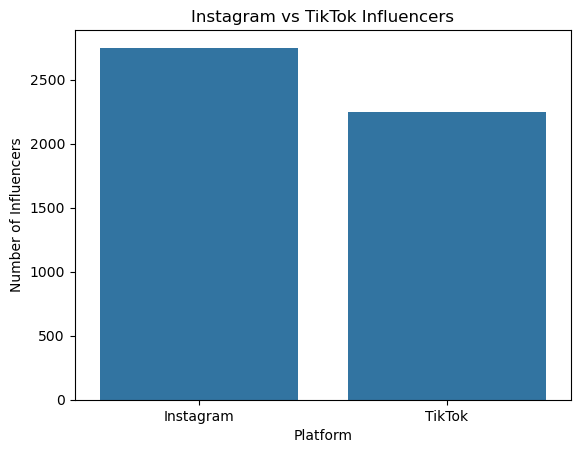

In [11]:
sns.countplot(data=df, x='platform')
plt.title("Instagram vs TikTok Influencers")
plt.xlabel("Platform")
plt.ylabel("Number of Influencers")
plt.show()


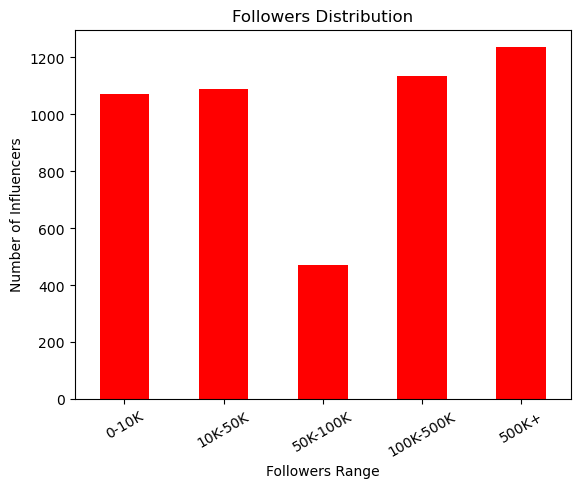

In [12]:
bins = [0, 10000, 50000, 100000, 500000, float('inf')]
labels = ['0-10K', '10K-50K', '50K-100K', '100K-500K', '500K+']

df['follower_range'] = pd.cut(df['followers'], bins=bins, labels=labels)
df['follower_range'].value_counts().sort_index().plot(kind='bar', color='red')

plt.title('Followers Distribution')
plt.xlabel('Followers Range')
plt.ylabel('Number of Influencers')
plt.xticks(rotation=30)
plt.show()


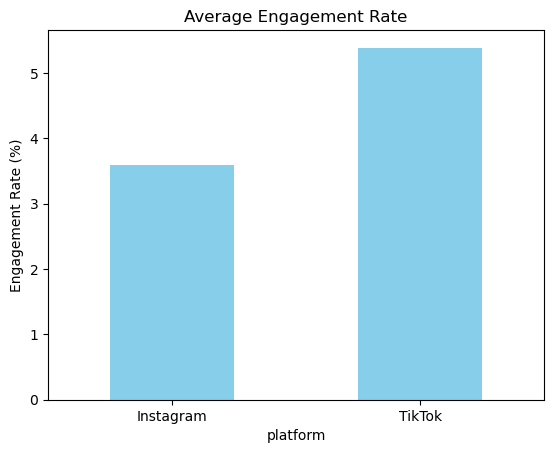

In [13]:
df.groupby('platform')['engagement_rate_pct'].mean().plot(kind='bar', color='skyblue')
plt.title('Average Engagement Rate')
plt.ylabel('Engagement Rate (%)')
plt.xticks(rotation=0)
plt.show()


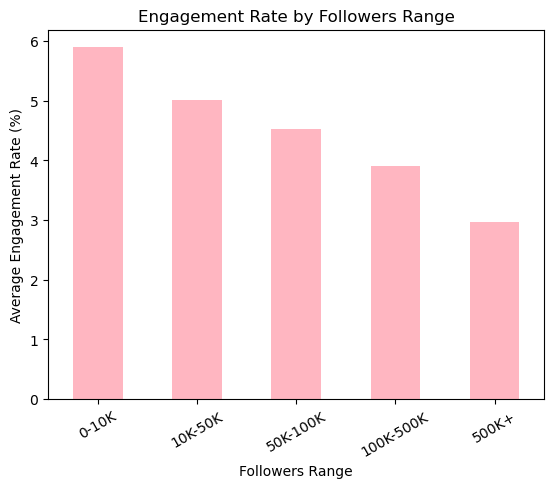

In [14]:
ax = df.groupby('follower_range', observed=True)['engagement_rate_pct'].mean().plot(kind='bar', color='lightpink')
plt.title('Engagement Rate by Followers Range')
plt.xlabel('Followers Range')
plt.ylabel('Average Engagement Rate (%)')
plt.xticks(rotation=30)
plt.show()


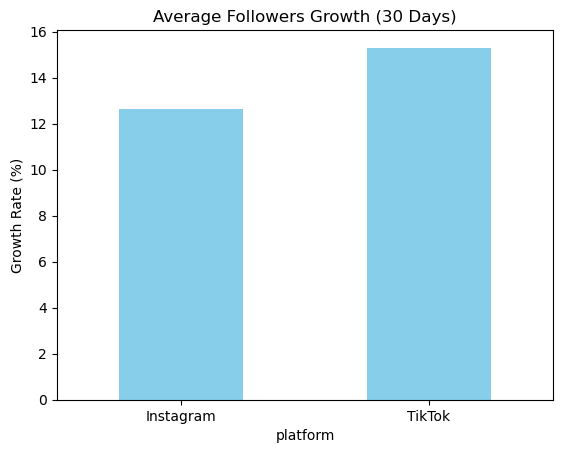

In [15]:
ax = df.groupby('platform')['followers_growth_30d_pct'].mean().plot(kind='bar', color='skyblue')
plt.title('Average Followers Growth (30 Days)')
plt.ylabel('Growth Rate (%)')
plt.xticks(rotation=0)
plt.show()


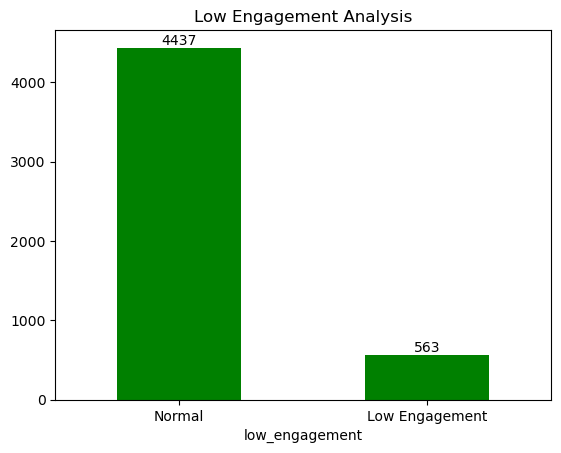

In [16]:
df['low_engagement'] = df['engagement_rate_pct'] < 1

ax = df['low_engagement'].value_counts().reindex([False, True], fill_value=0).plot(kind='bar', color='green')
ax.bar_label(ax.containers[0])
plt.title('Low Engagement Analysis')
plt.xticks([0, 1], ['Normal', 'Low Engagement'], rotation=0)
plt.show()


# Feature Selection

**Objective:** Select relevant features that can help identify unusual influencer engagement patterns and potential fraud.

The project uses two feature sets during modeling:

- **Initial model:** Uses 8 features listed in the code cell below for the baseline anomaly-detection model.
- **Improved model:** Uses 4 selected features that describe follower growth and engagement patterns.

The four features used in the improved model are:

- **Followers Growth (30 Days):** Percentage change in followers over 30 days.
- **Comment-to-Like Ratio:** Comments compared with likes, expressed as a percentage.
- **Views per Like:** Average views per post divided by average likes per post.
- **Likes Percentage:** Average likes as a percentage of follower count.

These four features are created or selected in the improved-model section.

In [17]:
features = [
    'engagement_rate_pct',
    'followers_growth_30d_pct',
    'followers_growth_90d_pct',
    'comment_like_ratio_pct',
    'view_follower_ratio',
    'following_follower_ratio',
    'monthly_post_frequency',
    'growth_acceleration_ratio'
]

In [18]:
X = df[features]

In [19]:
X.head()

,engagement_rate_pct,followers_growth_30d_pct,followers_growth_90d_pct,comment_like_ratio_pct,view_follower_ratio,following_follower_ratio,monthly_post_frequency,growth_acceleration_ratio
0,3.8247,5.79,18.65,6.1082,0.18974,0.00346,15.04,0.9319
1,2.8101,2.41,12.70,4.6578,0.28982,0.01601,28.06,0.5693
2,1.4578,3.02,6.71,7.1767,0.15885,0.00087,26.22,1.3493
3,1.8465,4.03,10.56,3.9013,0.13086,0.01379,22.74,1.1434
4,5.0846,0.92,-2.81,10.9726,0.20475,0.15973,5.57,-0.9830


In [20]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [21]:
iso = IsolationForest(n_estimators=100, contamination=0.1, random_state=42)
iso.fit(X_scaled)


,n_estimators,100
,max_samples,'auto'
,contamination,0.1
,max_features,1.0
,bootstrap,False
,n_jobs,None
,random_state,42
,verbose,0
,warm_start,False


In [22]:
df['iso_prediction'] = iso.predict(X_scaled)
df['iso_prediction'].value_counts()


iso_prediction
 1    4500
-1     500
Name: count, dtype: int64

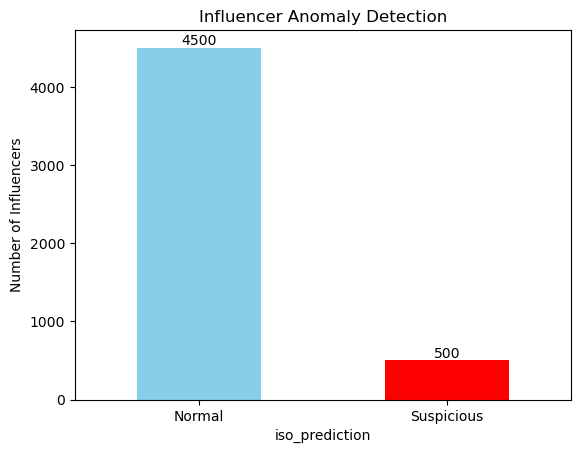

In [23]:
counts = df['iso_prediction'].map({1:'Normal', -1:'Suspicious'}).value_counts()
ax = counts.plot(kind='bar', color=['skyblue', 'red'])
ax.bar_label(ax.containers[0])
plt.title('Influencer Anomaly Detection')
plt.ylabel('Number of Influencers')
plt.xticks(rotation=0)
plt.show()


In [24]:
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.1)

df['lof_prediction'] = lof.fit_predict(X_scaled)
df['lof_prediction'].value_counts()


lof_prediction
 1    4500
-1     500
Name: count, dtype: int64

In [25]:
pd.crosstab(
    df['iso_prediction'],
    df['lof_prediction'],
    rownames=['Isolation Forest'],
    colnames=['LOF']
)

LOF,-1,1
Isolation Forest,,
-1,137,363
1,363,4137


# Risk Scoring and Business Decisions

**Objective:** Convert anomaly detection results into understandable fraud risk scores and practical business decisions.

The aim is to assign each influencer a risk score between 0 and 100, categorize profiles into different risk levels, and recommend suitable verification actions based on their suspicious engagement patterns.

The risk levels are:
- **Low Risk (0–69):** Basic Check
- **Medium Risk (70–89):** Manual Review
- **High Risk (90–100):** Detailed Verification

In [26]:
    
iso_risk = pd.Series(-iso.score_samples(X_scaled)).rank(pct=True)
lof_risk = pd.Series(-lof.negative_outlier_factor_).rank(pct=True)

df['fraud_risk_score'] = ((iso_risk + lof_risk) * 50).round(1)

df[['platform', 'fraud_risk_score']].head()


,platform,fraud_risk_score
0,Instagram,5.4
1,Instagram,23.6
2,Instagram,37.0
3,Instagram,27.9
4,Instagram,83.0


In [27]:
df['risk_level'] = pd.cut(df['fraud_risk_score'],
                          bins=[0, 70, 90, 101],
                          labels=['Low', 'Medium', 'High'], right=False)

df['vetting_action'] = df['risk_level'].map({
    'Low': 'Basic Check',
    'Medium': 'Manual Review',
    'High': 'Detailed Verification'
})

df[['fraud_risk_score', 'risk_level', 'vetting_action']].head()


,fraud_risk_score,risk_level,vetting_action
0,5.4,Low,Basic Check
1,23.6,Low,Basic Check
2,37.0,Low,Basic Check
3,27.9,Low,Basic Check
4,83.0,Medium,Manual Review


In [28]:
df['risk_level'].value_counts()

risk_level
Low       3795
Medium     997
High       208
Name: count, dtype: int64

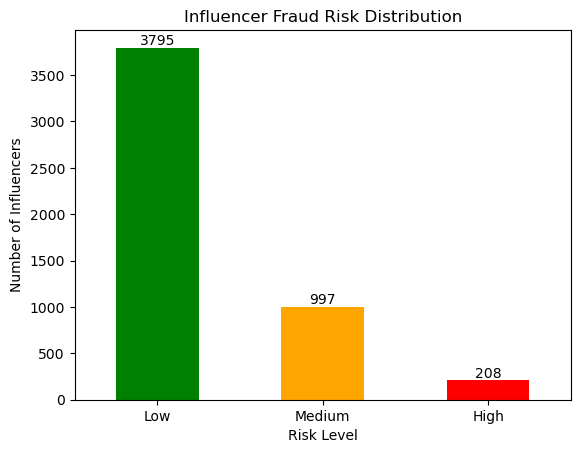

In [29]:

counts = df['risk_level'].value_counts().sort_index()

ax = counts.plot(kind='bar', color=['green', 'orange', 'red'])
ax.bar_label(ax.containers[0])

plt.title('Influencer Fraud Risk Distribution')
plt.xlabel('Risk Level')
plt.ylabel('Number of Influencers')
plt.xticks(rotation=0)
plt.show()


In [30]:
df.to_csv('influencer_fraud_risk_scores.csv', index=False)

print("CSV File Saved Successfully!")


CSV File Saved Successfully!


# Main Model Validation and Improved Model

**Objective:** Evaluate the initial anomaly-detection approach as an exploratory baseline and assess the improved model using a separate set of 200 reference-labeled influencer profiles.

### Initial Baseline — Exploratory Result

The initial Isolation Forest, LOF, and scaler were fitted using the full main dataset. The validation profiles were also present in this dataset, so the initial metrics are not an independent holdout evaluation. These results are retained only as exploratory baseline results.

### Improved Model Validation

The improved Isolation Forest model is fitted only on profiles whose `profile_id` is not present in the validation dataset. It is then evaluated against the supplied reference labels using precision and recall. These are the primary validation metrics for this project.

### Validation Note

The validation dataset contains 200 influencer profiles with reference labels. These labels are used as reference targets to evaluate the model. The source and independent manual verification of these labels are not documented. Therefore, the reported precision and recall represent performance against the supplied reference labels and should not be interpreted as confirmed real-world fraud detection performance.

In [31]:
validation_df = pd.read_csv(r"C:\Users\Admin\Downloads\Model validation.csv")

In [32]:
validation_df.shape

(200, 22)

In [33]:
check = validation_df.merge(
    df[['profile_id', 'fraud_risk_score']], on='profile_id')

check['actual_fraud'] = (check['reference_label'] == 'Fraud').astype(int)
check['predicted_fraud'] = (check['fraud_risk_score'] >= 70).astype(int)

print("Matched Profiles:", len(check))

Matched Profiles: 200


In [34]:
check.head()

,profile_id,handle,platform,category,country,account_age_months,followers,following,posts_count,avg_likes_per_post,...,comment_like_ratio_pct,view_follower_ratio,following_follower_ratio,monthly_post_frequency,growth_acceleration_ratio,reference_label,label_source,fraud_risk_score,actual_fraud,predicted_fraud
0,INF04802,@tiktok_sample_04802,TikTok,Technology,United Kingdom,11,14672,178,23,747,...,2.5435,0.31741,0.01213,13.90,0.9668,Genuine,Simulated scenario (NOT human verified),39.3,0,0
1,INF04420,@tiktok_sample_04420,TikTok,Food,Mexico,49,10981,933,553,416,...,9.3750,0.76004,0.08496,15.59,1.0093,Genuine,Simulated scenario (NOT human verified),71.2,0,1
2,INF04960,@tiktok_sample_04960,TikTok,Fitness,Indonesia,93,481742,1356,314,25290,...,31.5540,0.09088,0.00281,11.45,0.9536,Fraud,Simulated scenario (NOT human verified),46.4,1,0
3,INF00805,@instagram_sample_00805,Instagram,Business,Philippines,90,2454,377,503,105,...,8.5714,0.37816,0.15363,21.35,1.2350,Genuine,Simulated scenario (NOT human verified),49.1,0,0
4,INF00919,@instagram_sample_00919,Instagram,Music,Japan,73,808643,1570,309,2411,...,9.0834,0.02249,0.00194,11.28,4.8287,Fraud,Simulated scenario (NOT human verified),46.4,1,0


In [35]:
print("Initial baseline results (exploratory; not independent holdout validation)")
print("Accuracy:", accuracy_score(check['actual_fraud'], check['predicted_fraud']))

print(classification_report(
    check['actual_fraud'],
    check['predicted_fraud'],
    target_names=['Genuine', 'Fraud'],
    zero_division=0))

Initial baseline results (exploratory; not independent holdout validation)
Accuracy: 0.71
              precision    recall  f1-score   support

     Genuine       0.77      0.81      0.79       135
       Fraud       0.56      0.51      0.53        65

    accuracy                           0.71       200
   macro avg       0.67      0.66      0.66       200
weighted avg       0.70      0.71      0.71       200



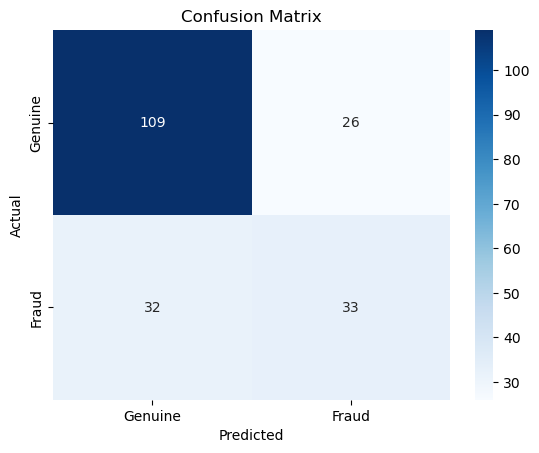

In [36]:
cm = confusion_matrix(check['actual_fraud'], check['predicted_fraud'])

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Genuine', 'Fraud'],
            yticklabels=['Genuine', 'Fraud'])

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()


In [37]:
df['views_per_like'] = df.avg_views_per_post / df.avg_likes_per_post
df['likes_pct'] = df.avg_likes_per_post / df.followers * 100

cols = ['followers_growth_30d_pct', 'comment_like_ratio_pct', 'views_per_like', 'likes_pct']
train = df.loc[~df.profile_id.isin(validation_df.profile_id), cols]

sc = StandardScaler().fit(train)
model2 = IsolationForest(random_state=42).fit(sc.transform(train))

df['risk_v2'] = pd.Series(-model2.score_samples(sc.transform(df[cols])), index=df.index).rank(pct=True)*100

test = validation_df.merge(df[['profile_id','risk_v2']], on='profile_id')
actual = test.reference_label.eq('Fraud')
predicted = test.risk_v2 >= 90

print('Precision:', precision_score(actual, predicted))
print('Recall:', recall_score(actual, predicted))


Precision: 0.8888888888888888
Recall: 0.36923076923076925


In [38]:

df['fraud_risk_score'] = df['risk_v2'].round(1)

df['risk_level'] = pd.cut(df['risk_v2'], [0,70,90,101],
                          labels=['Low','Medium','High'], right=False)

df['vetting_action'] = df['risk_level'].map({
    'Low':'Basic Check',
    'Medium':'Manual Review',
    'High':'Detailed Verification'
})

df.to_csv('influencer_fraud_final.csv', index=False)
print('Final CSV Saved!')


Final CSV Saved!


# Supplementary BON Dataset Experiment

**Objective:** Conduct an additional experiment using the BON dataset to examine how the developed anomaly detection model performs on a separate influencer dataset.

The aim is to prepare the BON dataset, create the required engagement features, apply the trained Isolation Forest model, and evaluate its ability to identify potentially fraudulent profiles using a calibrated risk-score threshold.

This experiment is supplementary and provides an additional performance check beyond the main validation dataset.

In [39]:
bon_df = pd.read_csv('bon_dataset.csv')

In [40]:
bon_df.head()

,profile_id,archetype,is_fraud,fraud_severity,case_type,niche,follower_count,following_count,posts_count,account_age_months,...,view_follower_ratio,growth_spike_score,audience_geo_mismatch,audience_real_ratio,comment_authenticity,profile_pic_flag,bio,sample_comments,post_caption,audience_note
0,BON-00001,lightly_boosted,0,32.9,normal,beauty,102332,1890,1297,85,...,0.82,0.436,0.158,0.638,0.519,0,Beauty lover sharing tips - Follow for makeup ...,Great tips as always! || Love your skin! #beau...,Spring Skin Refresh - How to Achieve Radiant G...,My audience loves natural beauty and simple sk...
1,BON-00002,click_farm_audience,1,77.6,normal,wellness,908685,13906,48,31,...,1.82,0.654,0.702,0.494,0.577,0,Always sharing wellness tips in English & Span...,Great tips! #healthandfitness 💪🏼 || Love your ...,Starting my week right with a healthy smoothie...,My audience loves diverse wellness advice - bo...
2,BON-00003,micro_real,0,11.5,trap_clean,tech,1982,49,73,90,...,1.60,0.260,0.272,0.835,0.730,0,Tech enthusiast sharing daily tech tips & revi...,"Love your tech insights! 👍 || Great tips, alwa...",Check out our latest project - #AI advancement...,"Small, engaged community passionate about tech..."
3,BON-00004,bought_followers,1,69.0,normal,food,281069,1896,2339,83,...,0.90,0.707,0.497,0.400,0.567,0,I share yummy recipes & cooking tips.,"Yum! Love your recipes! || Great pic, always h...",Fresh out of the oven - this cookie is a hit!,My audience loves quick & easy recipes.
4,BON-00005,click_farm_audience,1,75.2,normal,photography,251847,6401,2146,110,...,0.76,0.421,0.814,0.480,0.433,0,I love shooting nature pics - beauty in every ...,Oh so pretty! 🌿- || Love your style. || Amazin...,Just shot this morning's sunrise. Can't wait t...,My followers are passionate about travel and w...


In [41]:
print(bon_df.shape)

(10042, 26)


In [42]:
bon_df.columns.tolist()

['profile_id',
 'archetype',
 'is_fraud',
 'fraud_severity',
 'case_type',
 'niche',
 'follower_count',
 'following_count',
 'posts_count',
 'account_age_months',
 'avg_likes',
 'avg_comments',
 'avg_views',
 'engagement_rate',
 'like_comment_ratio',
 'follower_following_ratio',
 'view_follower_ratio',
 'growth_spike_score',
 'audience_geo_mismatch',
 'audience_real_ratio',
 'comment_authenticity',
 'profile_pic_flag',
 'bio',
 'sample_comments',
 'post_caption',
 'audience_note']

In [43]:
bon_df['views_per_like'] = bon_df.avg_views / bon_df.avg_likes.replace(0, float('nan'))

bon_df['likes_pct'] = bon_df.avg_likes / bon_df.follower_count.replace(0, float('nan')) * 100

bon_df['comment_like_ratio_pct'] = bon_df.avg_comments / bon_df.avg_likes.replace(0, float('nan')) * 100

bon_df[['views_per_like', 'likes_pct', 'comment_like_ratio_pct']].head()

,views_per_like,likes_pct,comment_like_ratio_pct
0,34.932749,2.339444,1.587302
1,30.636105,5.929558,2.642861
2,20.165605,7.921292,2.547771
3,28.015768,3.226610,1.268056
4,14.017279,5.400104,1.352941


In [44]:
features_bon = ['views_per_like', 'likes_pct', 
                'comment_like_ratio_pct']

bon_df[features_bon].isna().sum()

views_per_like            0
likes_pct                 0
comment_like_ratio_pct    0
dtype: int64

In [45]:
X_train = df[features_bon]

sc_bon = StandardScaler()
X_train = sc_bon.fit_transform(X_train)

bon_model = IsolationForest(random_state=42)
bon_model.fit(X_train)

print("Model Trained Successfully!")


Model Trained Successfully!


In [46]:
train_scores = -bon_model.score_samples(X_train)
bon_X = sc_bon.transform(bon_df[features_bon])
bon_scores = -bon_model.score_samples(bon_X)

threshold = pd.Series(train_scores).quantile(0.90)
pred = bon_scores >= threshold

print("Precision:", precision_score(bon_df['is_fraud'], pred, zero_division=0))
print("Recall:", recall_score(bon_df['is_fraud'], pred, zero_division=0))


Precision: 0.5962581344902386
Recall: 0.3928188638799571


In [47]:
cal, test = train_test_split(
    bon_df, test_size=0.5,
    random_state=42, stratify=bon_df['is_fraud']
)

print(cal.shape, test.shape)


(5021, 29) (5021, 29)


In [48]:
scores = -bon_model.score_samples(sc_bon.transform(cal[features_bon]))

for q in [0.90, 0.95, 0.98, 0.99]:
    threshold = pd.Series(scores).quantile(q)
    pred = scores >= threshold
    precision = precision_score(cal['is_fraud'], pred)
    print(q, "Precision:", round(precision * 100, 2), "%")


0.9 Precision: 72.37 %
0.95 Precision: 80.16 %
0.98 Precision: 90.1 %
0.99 Precision: 100.0 %


In [49]:
threshold = pd.Series(scores).quantile(0.98)

test_scores = -bon_model.score_samples(
    sc_bon.transform(test[features_bon])
)

pred = test_scores >= threshold

print("Precision:", precision_score(test['is_fraud'], pred))
print("Recall:", recall_score(test['is_fraud'], pred))
print("Flagged Profiles:", pred.sum())


Precision: 0.9433962264150944
Recall: 0.03572704537334762
Flagged Profiles: 106


## Final Results

The improved Isolation Forest model achieved a fraud precision of **88.89%** and a recall of **36.92%** on the main validation dataset.

A precision of 88.89% means that most profiles flagged as potentially fraudulent were labeled as fraud in the validation data. The recall of 36.92% indicates that the model identified only a portion of all labeled fraudulent profiles.

The supplementary BON dataset experiment achieved a precision of **94.34%** and a recall of **3.57%**, with 106 profiles flagged for further review.

These results show that the model is more effective at identifying high-risk profiles with fewer false alerts than at detecting every potentially fraudulent profile. The results should be interpreted carefully because the main dataset is simulated and the BON experiment is supplementary.

## Business Questions

**Business Question 1: How accurately does the model identify potentially fraudulent influencer profiles?**

The improved Isolation Forest model achieved 88.89% fraud precision and 36.92% recall on the main validation dataset. This indicates that most flagged profiles were labeled as fraudulent, but the model missed a substantial portion of the labeled fraud cases.

**Business Question 2: How can businesses use the fraud risk scores?**

The model assigns each influencer a risk score between 0 and 100. Profiles with low risk can receive a basic check, medium-risk profiles can be sent for manual review, and high-risk profiles can undergo detailed verification. These scores can help prioritize reviews, but they do not confirm fraud.

**Business Question 3: What are the limitations of the model?**

The main dataset is simulated, and the model has relatively low recall. This means some potentially fraudulent profiles may not be detected. The supplementary BON experiment also had very low recall. Further testing on real-world, independently verified influencer data is required before using the model for actual business decisions.